# Features, discretization, transformation, and reduction

Phase I of *Prishtina Taxi Mobility*: what we derive from the clean points, at the level of points and of trips, and how we reduce it to a set of features Phases II and III can start from.

This notebook only reads what the pipeline wrote (`python -m taxi.pipeline run`, see the README). Every number below comes from those outputs, so the notebook and the tables in `reports/` cannot disagree.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from taxi import config, io

# Outputs of a --dev run instead of the full run (for testing the notebook only).
DEV = os.environ.get("TAXI_NOTEBOOK_DEV") == "1"
config.set_dev(DEV)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)


def figure(name):
    display(Image(filename=str(config.figures_dir() / f"{name}.png"), width=900))


def table(name):
    path = io.report_table_path(name)
    if not path.exists():
        print(
            f"{path.relative_to(ROOT)} does not exist yet: run the stage that writes it."
        )
        return None
    return pd.read_csv(path)


print("Reading the outputs of the", "dev run" if DEV else "full run")

Reading the outputs of the full run


## 1. Feature creation

The `features` stage adds columns to every clean point; nothing is dropped or changed. Each feature serves one of the guiding questions of the project:

- **Q1** When and where is the fleet most active?
- **Q2** How do speeds change across the day and across the city?
- **Q3** How much time do taxis spend moving, standing, or switched off?
- **Q4** What does a typical trip look like?
- **Q5** How do weekends differ from working days?

Time features come from the local time, motion features from the step that starts at the point (acceleration, change of heading), space features from the projection to metres, and circular values (hour, heading) get a sine and cosine so that 23:00 is close to 00:00 and 359 degrees close to 1 degree. The catalogue lists every created feature with its formula, unit, attribute type, and purpose.

In [2]:
catalog = table("feature_catalog")
print(catalog.groupby("dataset").size().to_string())
catalog[catalog["dataset"] == "processed/points"][["feature", "formula", "unit", "attribute_type", "purpose"]]

dataset
processed/model/trips_model          21
processed/model/vehicle_day_model    24
processed/points                     18
processed/trips                      13


,feature,formula,unit,attribute_type,purpose
0,dow,"ts_local day of week, 0 = Monday",NaN,"ordinal, circular","Q1 (day of week), Q5 (weekends vs working days)"
1,minute_of_week,dow * 1440 + hour * 60 + minute,min,"interval, circular","Q1, Q5: weekly activity profile (hour-of-week heatmaps)"
2,tod_bucket,"hour in [0, 6) night, [6, 10) morning, [10, 15) midday, [15, 19) afternoon, [19, 24) e...",NaN,"ordinal, circular","Q1, Q2: activity and speed by part of the day"
3,is_night,"hour in [0, 6)",NaN,"nominal (binary, symmetric)",Q1: night-time activity
4,is_moving,speed_kmh >= 5,NaN,"nominal (binary, symmetric)",Q3: moving vs standing time (time-weighted over steps)
5,accel_ms2,"(speed_next - speed) / 3.6 / dt_s, NA across gaps, dt_s = 0, or timestamps without sec...",m/s²,ratio,Q2: stop-and-go driving across the day and the city; Phase II: speed spikes
6,heading_change_deg,"circular |heading_next - heading|, 0-180, NA across gaps",degrees,ratio,"No guiding question directly (turning, GPS zig-zag for Phase II outliers): candidate t..."
7,compass8,45-degree sectors of heading centred on N,NaN,"nominal, circular","Q1, Q4: direction of flows, for example towards or away from the centre by hour"
8,speed_bin,"speed_kmh in [0, 5) stopped, [5, 20) slow, [20, 50) urban, [50, 80) fast, [80, inf) hi...",NaN,ordinal,"Q2, Q3: time spent in each speed regime"
9,x_m,"EPSG:32634 easting of (lon, lat)",m,interval,Q1 (where): distances and grid cells in metres


### Stops and trips: a new level of detail

A **stop** is a run of points that stays within `STOP_RADIUS_M` of its first point for at least `STOP_MIN_S`. A **trip** is cut by one of two rules, compared on all vehicles:

- `stop_gap`: the movement between two stops;
- `di2`: a run of points with the taximeter on.

The taximeter signal drops out for a few seconds at a time, so the `di2` rule first bridges short "off" interruptions. The length of those interruptions shows where to put the threshold: most are one or two missed reports, a second group is the time between two fares, and the counts are lowest in between.

In [3]:
print(f"STOP_RADIUS_M = {config.STOP_RADIUS_M}, STOP_MIN_S = {config.STOP_MIN_S}, DI2_BRIDGE_S = {config.DI2_BRIDGE_S}, TRIP_RULE = {config.TRIP_RULE}")
table("di2_interruptions")

STOP_RADIUS_M = 100, STOP_MIN_S = 300, DI2_BRIDGE_S = 60, TRIP_RULE = di2


,from_s,to_s,interruptions,share,cumulative_share,per_second,interruptions_minute_only,bridged
0,0,5.0,752146,0.6752,0.6752,150429.20,7212,True
1,5,10.0,102557,0.0921,0.7673,20511.40,0,True
2,10,15.0,27381,0.0246,0.7919,5476.20,0,True
3,15,20.0,17351,0.0156,0.8075,3470.20,0,True
4,20,30.0,17718,0.0159,0.8234,1771.80,0,True
5,30,40.0,9326,0.0084,0.8317,932.60,0,True
6,40,50.0,6331,0.0057,0.8374,633.10,0,True
7,50,60.0,4504,0.0040,0.8415,450.40,0,True
8,60,70.0,3640,0.0033,0.8447,364.00,660,False
9,70,80.0,2925,0.0026,0.8474,292.50,0,False


How much the trips change with the bridge threshold: around the chosen value, a few seconds more or less changes little.

In [4]:
sensitivity = table("di2_bridge_sensitivity")
sensitivity[["bridge_s", "chosen", "episodes", "duration_min_median", "distance_km_median", "share_under_1_min"]]

,bridge_s,chosen,episodes,duration_min_median,distance_km_median,share_under_1_min
0,0,False,1119372,0.08,0.028,0.8025
1,10,False,262792,4.20,1.276,0.3597
2,20,False,218064,5.80,1.766,0.2396
3,30,False,200349,6.42,1.947,0.1794
4,45,False,187688,6.90,2.091,0.1335
5,60,True,179923,7.22,2.185,0.1080
6,90,False,170871,7.62,2.302,0.0809
7,120,False,165200,7.90,2.378,0.0677
8,180,False,156619,8.32,2.502,0.0529
9,300,False,139892,9.23,2.790,0.0386


The two rules side by side, for all vehicles together. The `di2` rule describes paid rides, which is what "a typical trip" (Q4) asks about, so it is the rule of the trip table.

In [5]:
comparison = table("trip_rule_comparison")
comparison[comparison["vehicles"] == "all"].set_index("rule").T

rule,stop_gap,di2
vehicles,all,all
vehicle_days,6519,6519
vehicles_with_trips,83,77
trips,118619,179923
trips_per_vehicle_day_mean,18.2,27.6
trips_per_vehicle_day_median,19.0,29.0
duration_min_median,18.4,7.22
duration_min_p25,7.3,4.08
duration_min_p75,38.25,11.33
distance_km_median,5.773,2.185


**Checks on the trip table.** The stage stops if any check fails. Trips with fewer than 3 points or zero distance are flagged `flag_short`, not deleted: whether they are errors is a Phase II question.

In [6]:
trips = io.read_table("trips")
print(f"{len(trips):,} trips of {trips['vehicle_id'].nunique()} vehicles, {trips['flag_short'].sum():,} flagged short")
display(table("trip_checks"))
trips[["duration_s", "distance_m", "straightness", "avg_speed_kmh", "n_points"]].describe().T.round(2)

179,923 trips of 77 vehicles, 12,602 flagged short


,check,status,failing,total,note
0,every trip has at least 2 points,pass,0,179923,NaN
1,every trip has a positive duration,pass,0,179923,NaN
2,trips of one vehicle do not overlap,pass,0,179923,the next trip starts at or after the end of the previous one
3,"per vehicle, sum of trip distances <= sum of step distances without a gap",pass,0,83,NaN
4,"per vehicle, sum of trip distances <= sum of vehicle_day.km",pass,0,77,km is float32: tolerance 0.01% + 1 m
5,points: rows written = rows read (nothing dropped),pass,0,83,NaN


,count,mean,std,min,25%,50%,75%,max
duration_s,179923.0,521.47,480.98,1.0,245.00,433.00,680.00,17897.0
distance_m,179923.0,3236.34,5782.84,0.0,1224.85,2185.28,3559.99,258356.5
straightness,171240.0,0.70,0.18,0.0,0.60,0.72,0.82,1.0
avg_speed_kmh,179923.0,19.44,11.61,0.0,13.64,18.16,23.50,612.6
n_points,179923.0,64.89,55.83,2.0,33.00,54.00,84.00,2033.0


**The passenger input.** `Di3` is stuck true in some vehicles, also with the ignition off, where no passenger can be. A vehicle's `Di3` is marked unreliable when it is true for more than `DI3_STUCK_SHARE` of its ignition-off time; the raw values stay unchanged, and `vehicle_day_model` sets their `di3_share` to NA.

In [7]:
di3 = table("di3_reliability")
print(f"DI3_STUCK_SHARE = {config.DI3_STUCK_SHARE}")
di3.groupby("di3_reliable")["di3_off_share"].agg(["count", "min", "median", "max"]).round(4)

DI3_STUCK_SHARE = 0.5


,count,min,median,max
di3_reliable,,,,
False,25,0.5142,0.9985,0.9998
True,58,0.0000,0.0009,0.1083


## 2. Discretization and binarization

Every bin is left-closed, `[a, b)`. With right-closed bins a speed of exactly 0 would fall outside the first bin. Speed, time of day, and heading use domain-based edges that mean something (stopped, city driving, highway). For trip distance, three methods are compared: equal width, equal frequency, and domain-based edges. With a long right tail, equal-width bins put almost every trip in the first bin.

In [8]:
bins = table("discretization_bins")
distance = bins[bins["variable"] == "trip distance_m"]
distance.pivot_table(index="bin", columns="method", values="count", sort=False)

method,equal_width,equal_frequency,domain
bin,,,
"[0.00, 51.67) km",179430.0,NaN,NaN
"[51.67, 103.34) km",419.0,NaN,NaN
"[103.34, 155.01) km",64.0,NaN,NaN
"[155.01, 206.69) km",6.0,NaN,NaN
"[206.69, 258.36) km",4.0,NaN,NaN
"[0.00, 0.96) km",NaN,35985.0,NaN
"[0.96, 1.82) km",NaN,35984.0,NaN
"[1.82, 2.62) km",NaN,35985.0,NaN
"[2.62, 4.03) km",NaN,35984.0,NaN


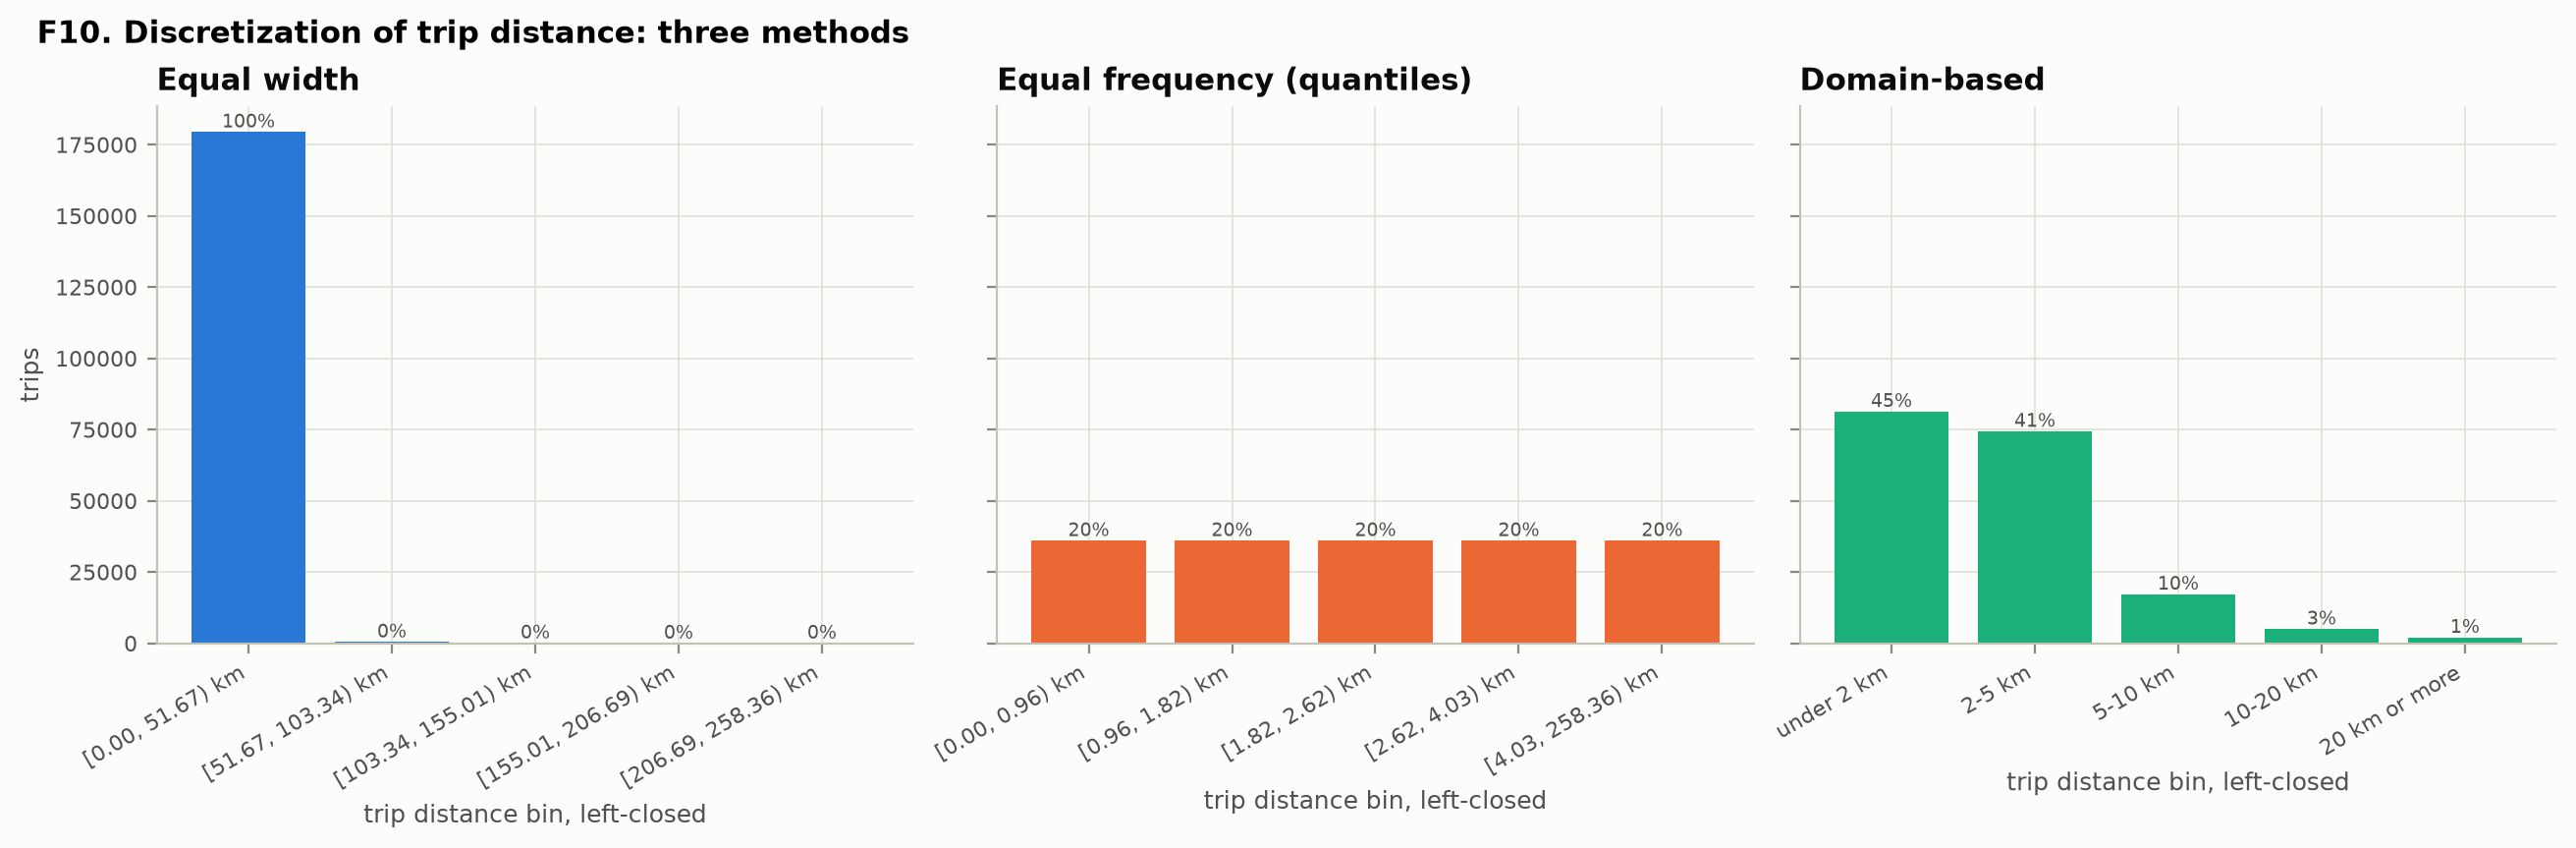

In [9]:
figure("f10_discretization")

Binary attributes are stored as 0/1 with NA kept as NA. An attribute is **asymmetric** when only its 1s carry information (a holiday, a short-trip flag): for similarity in Phase II, two trips that are both "not on a holiday" should not count as alike, so measures such as Jaccard suit those columns better than simple matching.

In [10]:
table("binarization_summary")

,column,dataset,n,ones,zeros,na,share_ones_points,share_ones_time,asymmetric,note
0,is_moving,processed/points,28516912,17664144,10852768,0,0.6194,0.2819,False,moving and standing are both informative states
1,is_weekend,processed/points,28516912,5937268,22579644,0,0.2082,0.2839,False,weekend and working day are both informative
2,is_night,processed/points,28516912,3383782,25133130,0,0.1187,0.2446,False,night and day are both informative
3,is_holiday,processed/points,28516912,171533,28345379,0,0.0060,0.0108,True,only the one holiday is informative; two ordinary days are not alike because neither i...
4,di1,processed/points,28516912,27467541,1049371,0,0.9632,0.4473,False,ignition on and off are both informative states
5,di2,processed/points,28516912,10355467,18161441,4,0.3631,0.1663,True,taximeter on marks a paid ride; off is the default state
6,di3,processed/points,28516912,12490562,16026346,4,0.4380,0.3598,True,a passenger on board is the event of interest; stuck in 25 vehicles
7,in_kosovo,processed/points,28516912,28416667,100245,0,0.9965,0.9980,True,the rare value (outside Kosovo) is the informative one
8,gap_after,processed/points,28516912,5969,28510943,0,0.0002,NaN,True,quality flag: only a gap carries information
9,speed_imputed,processed/points,28516912,0,28516912,0,0.0000,0.0000,True,quality flag


## 3. Transformation

- **Units:** km/h to m/s where a formula needs SI units (acceleration).
- **Projection:** latitude and longitude to metres in EPSG:32634 (`x_m`, `y_m`).
- **Log:** `log1p` of the long-tailed size variables, kept only where it lowers the skewness.
- **Scaling:** z-scores of the model features, fitted on the whole table, because PCA and distance-based methods would otherwise be dominated by the feature with the largest units.

In [11]:
table("transformation_skewness")

,table,feature,n,skew_raw,skew_log1p,kept,column
0,trips_model,distance_m,179923,11.062,-2.212,log1p,distance_m_log
1,trips_model,duration_s,179923,4.216,-1.864,log1p,duration_s_log
2,trips_model,straight_m,179923,11.221,-2.094,log1p,straight_m_log
3,trips_model,n_points,179923,4.005,-1.177,log1p,n_points_log
4,trips_model,start_dist_center_m,179923,15.653,0.085,log1p,start_dist_center_m_log
5,trips_model,end_dist_center_m,179923,13.203,0.156,log1p,end_dist_center_m_log
6,vehicle_day_model,km,6519,0.399,-2.090,raw,km
7,vehicle_day_model,n_trips,6157,-0.083,-1.620,raw,n_trips
8,vehicle_day_model,trip_median_distance_m,5355,22.326,-5.677,log1p,trip_median_distance_m_log
9,vehicle_day_model,trip_median_duration_s,5355,9.682,-4.120,log1p,trip_median_duration_s_log


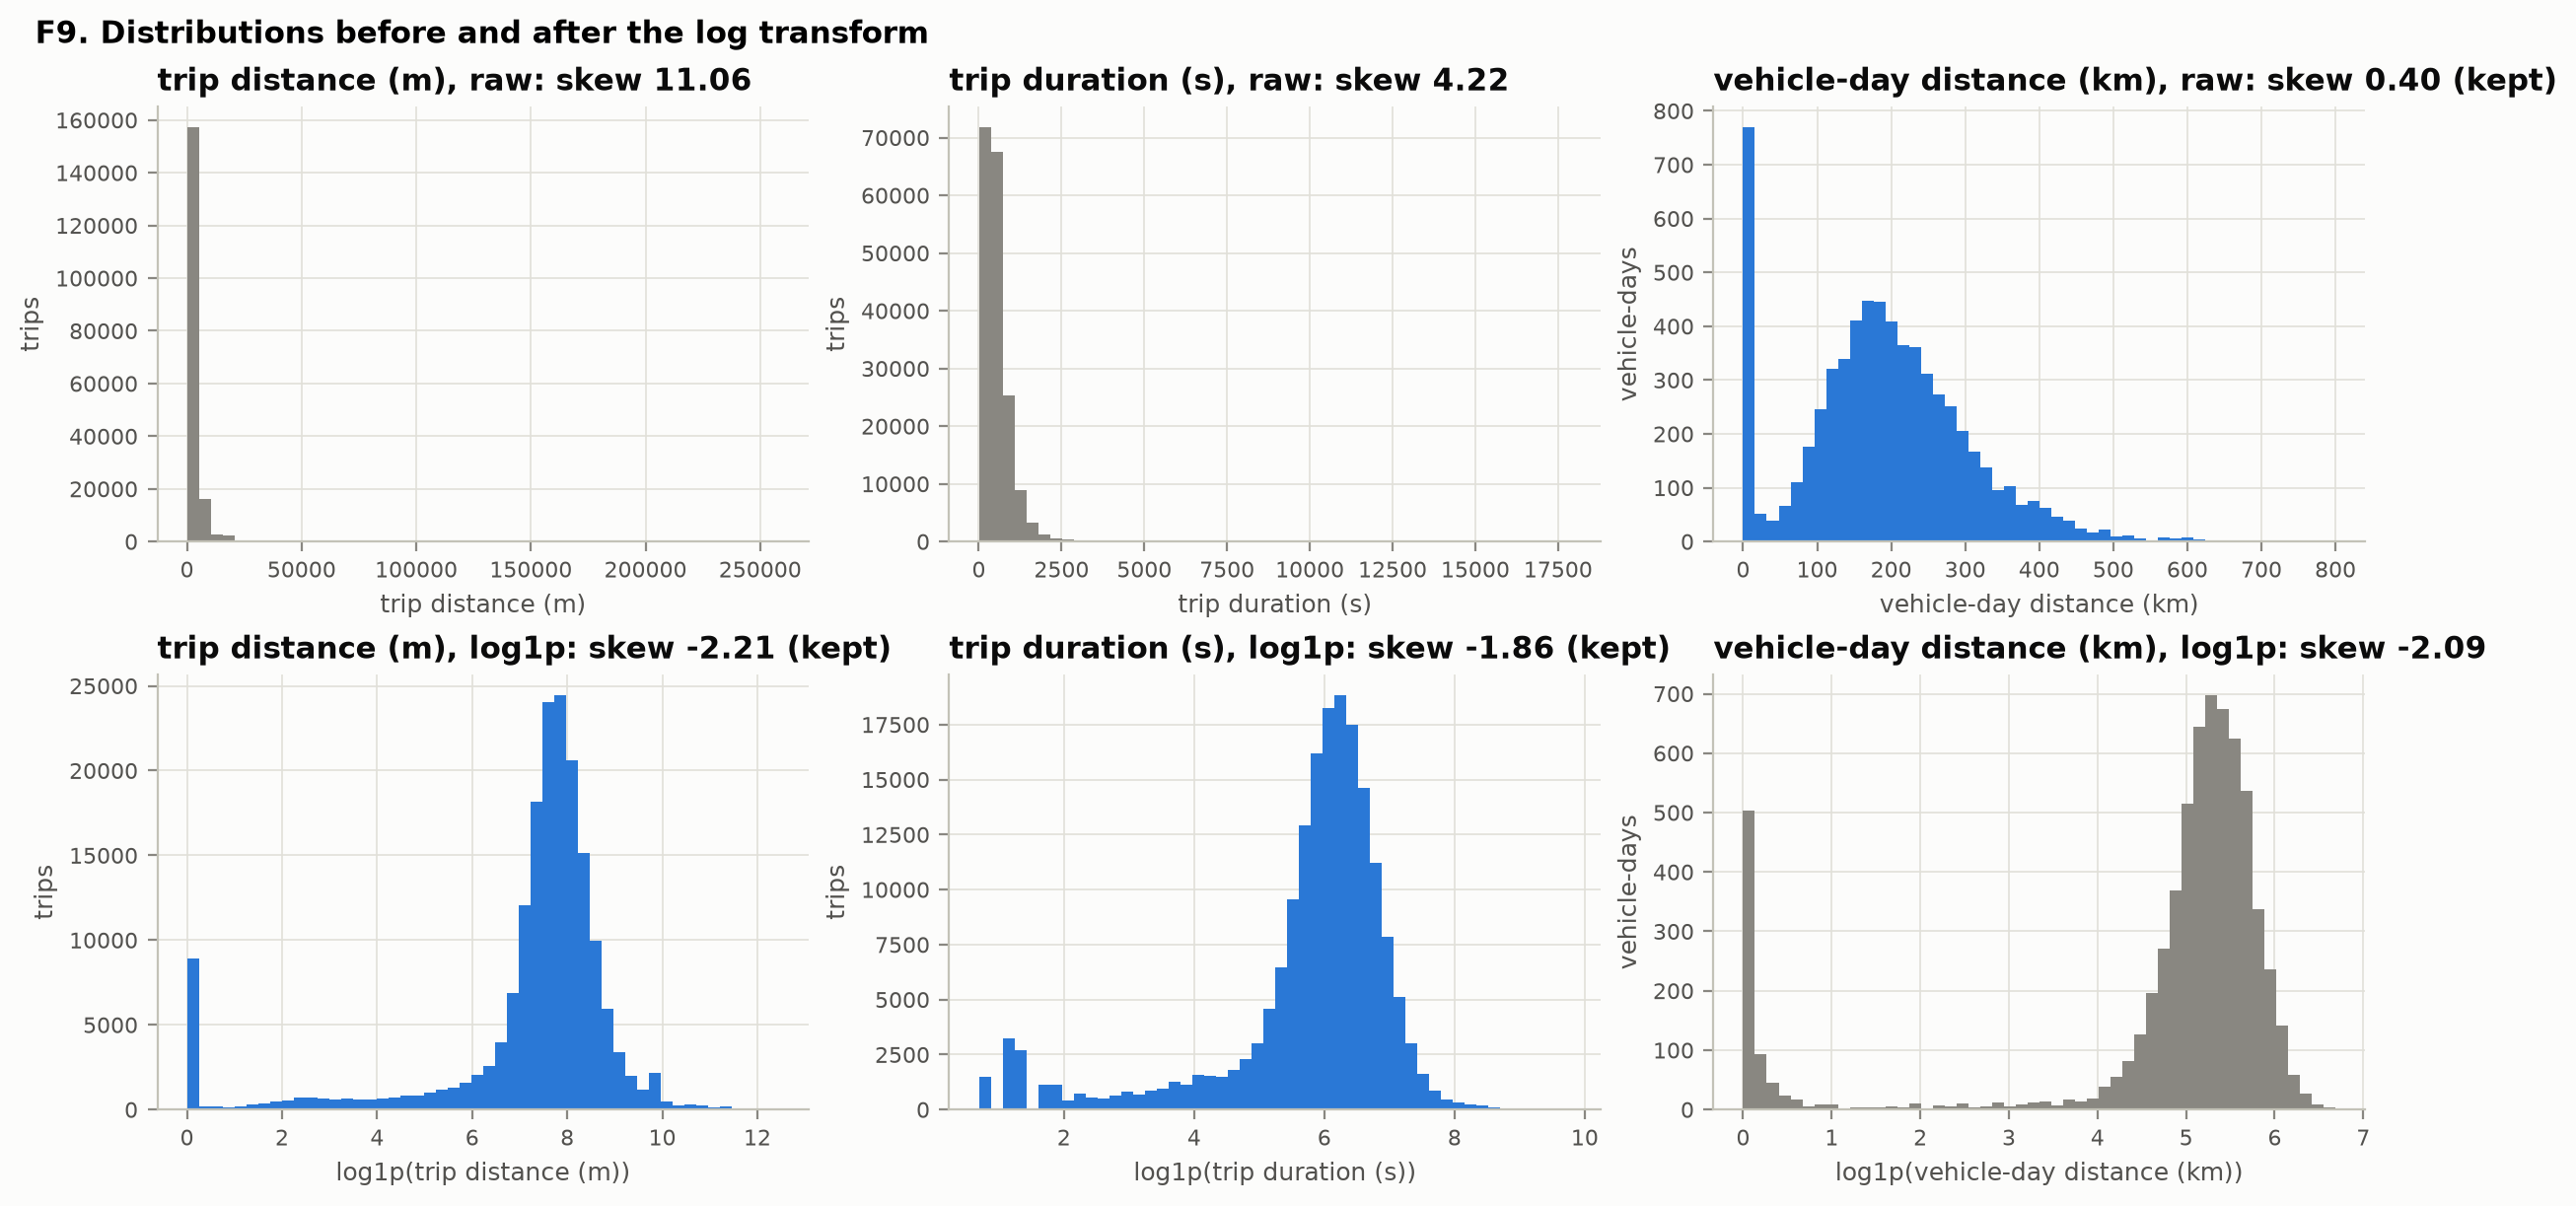

In [12]:
figure("f09_transformations")

## 4. Feature subset selection and dimensionality reduction

There is no target variable, so the selection uses filter methods on the two model tables: identifiers and timestamps out; near-constant features out (one value in at least 95% of the rows, judged on the unscaled values, since every z-score has variance 1); then, for every pair with |r| of at least 0.9, the one easier to interpret stays. What remains is checked against the guiding questions.

In [13]:
selection = table("feature_selection")
print(selection.groupby(["table", "decision"]).size().to_string())
selection[selection["decision"] == "kept"][["table", "feature", "reason"]]

table              decision
trips_model        dropped     13
                   kept         9
vehicle_day_model  dropped     10
                   kept        10


,table,feature,reason
5,vehicle_day_model,km,"kept: informative, not redundant, serves a guiding question"
6,vehicle_day_model,avg_speed_moving_kmh,"kept: informative, not redundant, serves a guiding question"
7,vehicle_day_model,max_speed_kmh,"kept: informative, not redundant, serves a guiding question"
9,vehicle_day_model,di2_share,"kept: informative, not redundant, serves a guiding question"
13,vehicle_day_model,moving_share,"kept: informative, not redundant, serves a guiding question"
14,vehicle_day_model,n_trips,"kept: informative, not redundant, serves a guiding question"
15,vehicle_day_model,trip_median_distance_m_log,"kept: informative, not redundant, serves a guiding question"
16,vehicle_day_model,trip_median_duration_s_log,"kept: informative, not redundant, serves a guiding question"
17,vehicle_day_model,night_trip_share,"kept: informative, not redundant, serves a guiding question"
18,vehicle_day_model,is_weekend,"kept: informative, not redundant, serves a guiding question"


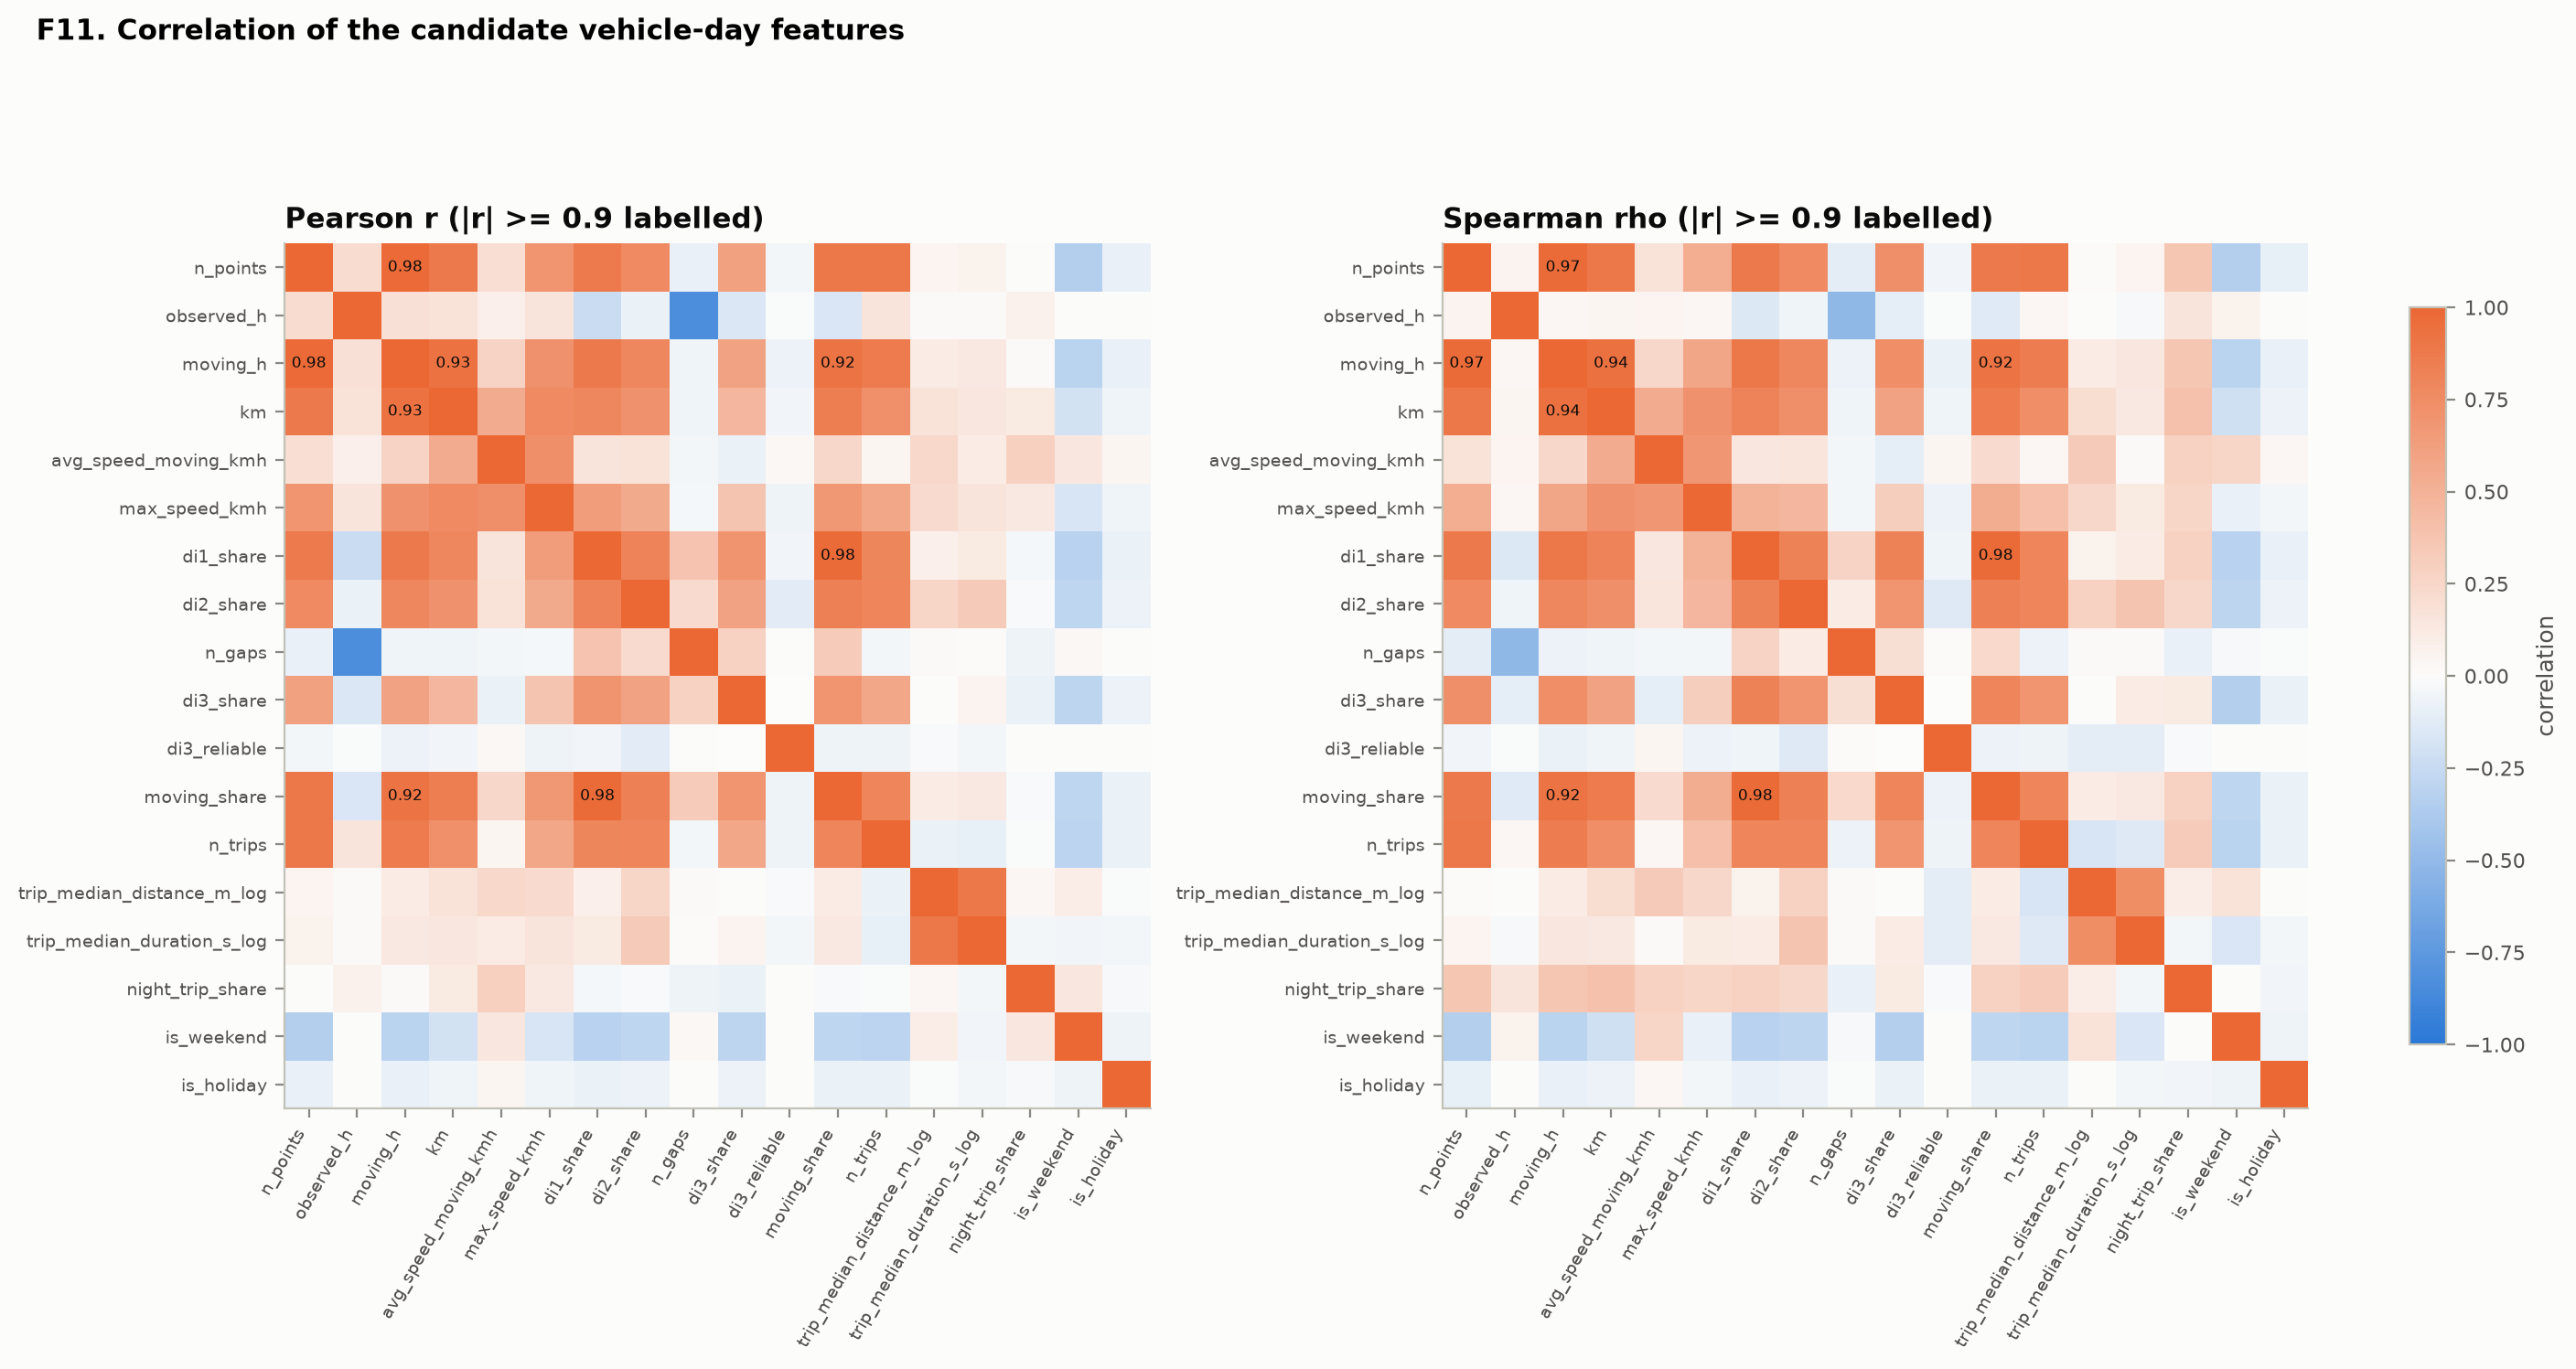

In [14]:
figure("f11_feature_correlation")

**PCA** on the z-scores of the kept vehicle-day features. The number of components kept is the smallest that explains `PCA_VARIANCE_TARGET` of the variance; the scores `pc1`, `pc2`, ... are added to `vehicle_day_model` for Phases II and III. The same PCA on unscaled and min-max scaled data shows why scaling matters.

In [15]:
variance = table("pca_explained_variance")
print(f"PCA_VARIANCE_TARGET = {config.PCA_VARIANCE_TARGET}")
variance[variance["scaling"] == "zscore"][["component", "explained_variance_ratio", "cumulative_ratio", "kept"]]

PCA_VARIANCE_TARGET = 0.9


,component,explained_variance_ratio,cumulative_ratio,kept
0,pc1,0.325145,0.325145,True
1,pc2,0.239209,0.564355,True
2,pc3,0.180108,0.744463,True
3,pc4,0.101781,0.846244,True
4,pc5,0.083738,0.929981,True
5,pc6,0.026934,0.956916,False
6,pc7,0.015915,0.972831,False
7,pc8,0.012530,0.985361,False
8,pc9,0.009904,0.995265,False
9,pc10,0.004735,1.000000,False


The loadings say what each component measures: the features with the largest absolute weight on it.

In [16]:
loadings = table("pca_loadings").set_index("feature")
for pc in ["pc1", "pc2"]:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(4)
    print(pc, ", ".join(f"{name} {weight:+.2f}" for name, weight in top.items()))

pc1 km +0.45, di2_share +0.45, moving_share +0.43, trip_median_duration_s_log +0.35
pc2 trip_median_distance_m_log +0.56, trip_median_duration_s_log +0.51, n_trips -0.38, is_weekend +0.29


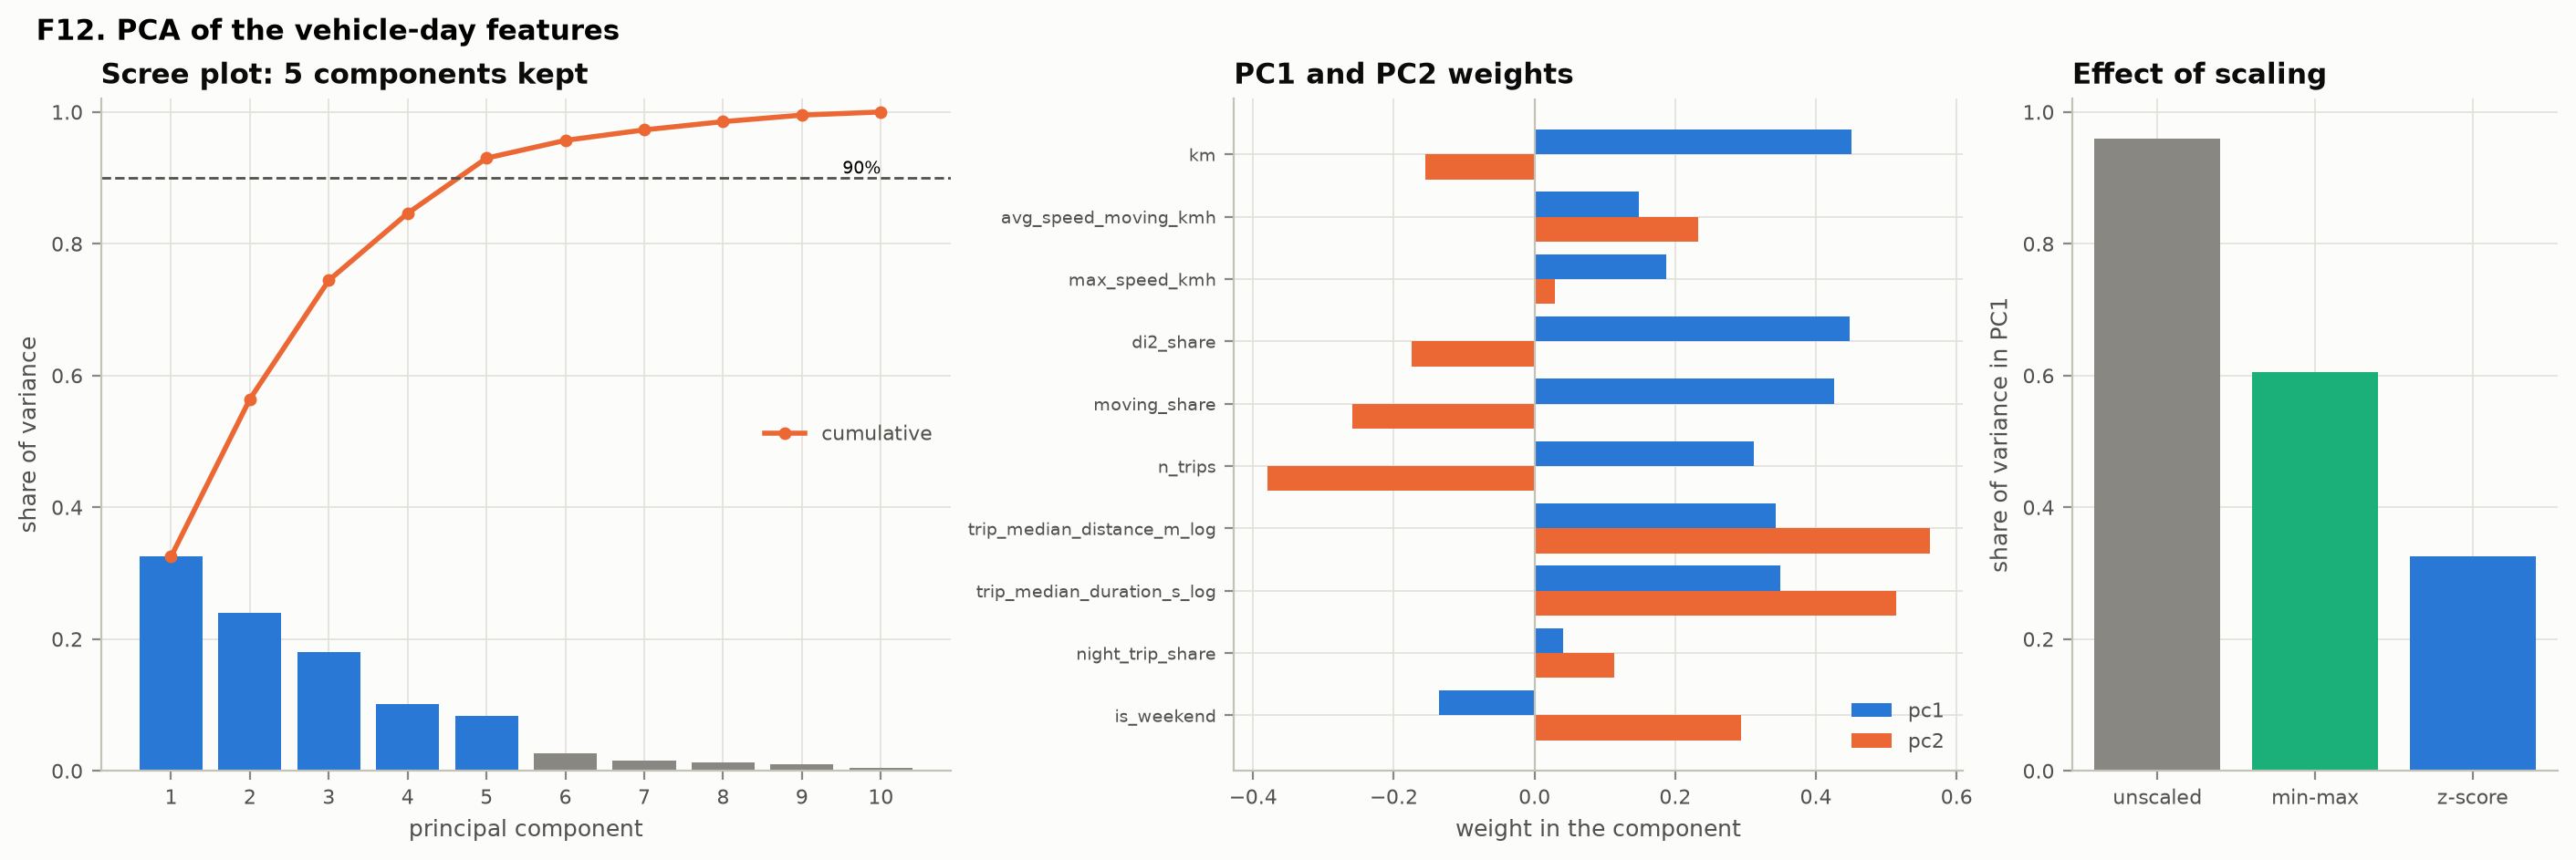

In [17]:
figure("f12_pca_scree")

## 5. Output datasets

The `export` stage builds the package for submission after checking that every exported column has a row in the data dictionary. The manifest lists each file with its rows, columns, size, and SHA-256.

In [18]:
table("export_manifest")

,file,dataset,format,rows,columns,bytes,sha256
0,cell_hour.csv,processed/cell_hour,csv,611316.0,9,39371754,2137333fbc6a8e36fb6d555b2fefafb34dbb2a45b6c00b03e3b3f6696bbf5d67
1,data_dictionary.csv,NaN,csv,NaN,9,35747,3292031fcc9786c671dec74ef055ea1ef3d2b9d3192715c2d4587db2a2257a02
2,fleet_hour.csv,processed/fleet_hour,csv,2208.0,6,128982,657caa3b1ac947f309de12e1b627792e26d1117c7a49cc965dfcceeda39d8000
3,model/trips_model.parquet,processed/model/trips_model,parquet,179923.0,37,22014880,e6d933b6dd4875963cfd7daa39d7917d09e49720344c8d2fec842438a8a52bf1
4,model/vehicle_day_model.parquet,processed/model/vehicle_day_model,parquet,6519.0,43,958768,dd0367d14fa6449727e32fc420b0beabad4e286c35d91469c40e03f3c3433e45
...,...,...,...,...,...,...,...
87,points/99.parquet,processed/points,parquet,395930.0,43,25315508,0947f5db8b250a53084bcdc64219e69420486933a72c880b1be168fa6cb924bf
88,points_sample.csv,sample/points_sample,csv,21724.0,26,4510903,638b37f62e5b36779fc42146f869d29c6b97e34b182521d1aea97ee81ae623ac
89,trips.csv,processed/trips,csv,179923.0,20,34684399,acab3db06e9269a64af9a6ef42d8c2f55741e149c4a66e7aff72c2b421954274
90,trips.parquet,processed/trips,parquet,179923.0,20,9867636,1e510ca055c266a24997784a77d6ace06f12c16463848adbec3d19a334ebc43b
